# 冻结三个 Pareto 候选

## tl;dr
515 条共同样本上，25:75 的 Brier/LogScore 最好；REL/RES 细排随分档变化。找到 152 条首份可执行盘口、42 条新鲜权益记录，仍未绑定完整费用与执行合同，实际 EV / Log-growth 不可识别。

## Context & Methods
固定上一轮 25/50/75% 中心权重份额，未重训或择优分母。

### Key Assumptions
本窗已参与设计，为 retrospective-asof，不是独立未见 OOS；33 站、23 日、515 条。线性池未经过最终服务后处理。经济缺失不填零。

In [1]:
import json, hashlib,sys
from pathlib import Path
base=Path.cwd();sys.path.insert(0,str(base))
import evaluate as E
guard=E.C.study.Guard()
r=json.loads((base/'results.json').read_text())
v=json.loads((base/'validation.json').read_text())
f=json.loads((base/'candidates.json').read_text())
for name,sha in r['input_sha256'].items():
    assert hashlib.sha256((E.C.ROOT/name).read_bytes()).hexdigest()==sha
assert r['sample_n']==f['sample_n']==515
print('515 station-days; 33 stations; 23 dates; all rows have 11 buckets')

515 station-days; 33 stations; 23 dates; all rows have 11 buckets


## Data
冻结权重 hash 和共同样本 hash 在 candidates.json；逐样本评分在 scores.json。所有候选使用相同 515 条。

In [2]:
labels={'current': 'Current', 'blend25': '25:75', 'blend50': '50:50', 'blend75': '75:25'}
print(f"{'Candidate':10} {'Brier':>10} {'LogScore':>10} {'REL':>12} {'RES':>12}")
for a,label in labels.items():
    x=r['arms'][a];d=x['decomposition']['primary']
    assert abs(d['reliability']-d['resolution']+d['uncertainty']+d['binning_correction']-x['mean_bucket_brier'])<1e-12
    print(f"{label:10} {x['brier']:10.6f} {x['logscore']:10.6f} {d['reliability']:12.8f} {d['resolution']:12.8f}")
print('Independent scoring checks:',v['independent_brier_and_logscore_n'])

Candidate       Brier   LogScore          REL          RES
Current      0.730368  -1.584997   0.00100103   0.01685557
25:75        0.727989  -1.580667   0.00084768   0.01689723
50:50        0.728185  -1.581672   0.00087078   0.01695271
75:25        0.728505  -1.583013   0.00087961   0.01698923
Independent scoring checks: 2060


## Results
主分档的校准图；点为各档加权平均预测与经验频率。分档并不提供独立 OOS 校准证明。

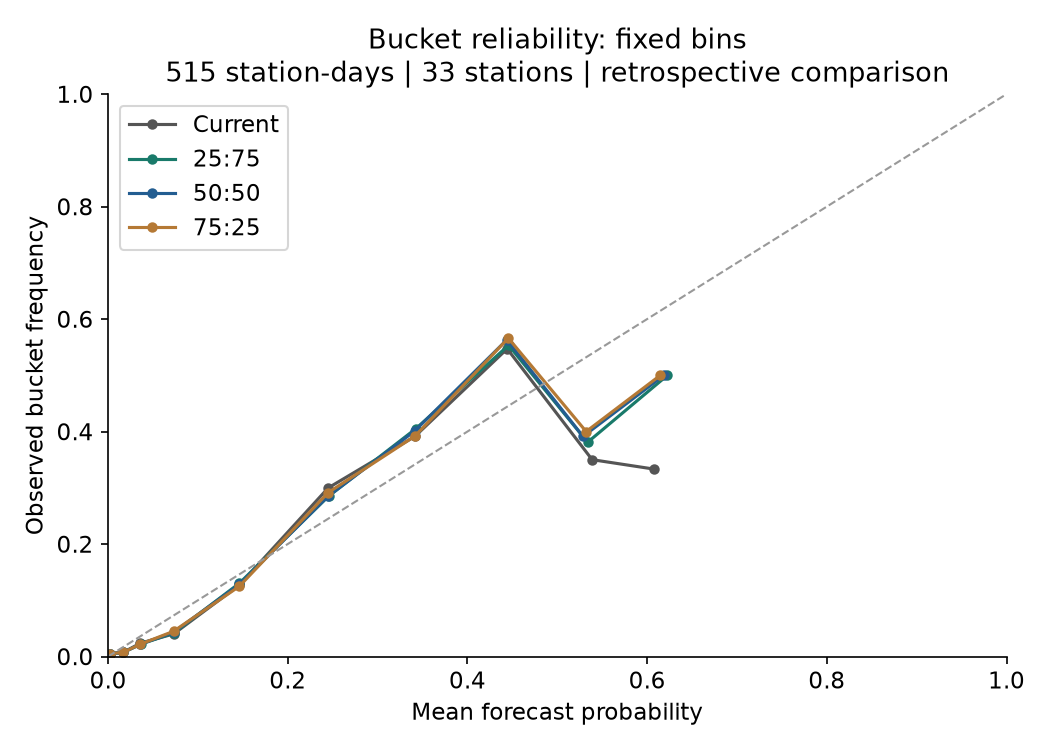

In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(7,5))
colors=['#555555','#197A6A','#235D91','#B57935']
for (a,label),color in zip(labels.items(),colors):
    bs=[b for b in r['arms'][a]['reliability_bins'] if b['event_weight']>0]
    ax.plot([b['mean_probability'] for b in bs],[b['observed_frequency'] for b in bs],marker='o',markersize=4,label=label,color=color)
ax.plot([0,1],[0,1],'--',color='#999999',linewidth=1)
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean forecast probability',ylabel='Observed bucket frequency',title='Bucket reliability: fixed bins\n515 station-days | 33 stations | retrospective comparison')
ax.legend();fig.tight_layout();fig.savefig(base/'reliability.png',dpi=150);plt.close(fig)
display(Image(filename=str(base/'reliability.png')))

主分档偏好 25:75 的 Reliability；20 档则略偏好 75:25。不可按本窗挑分档宣布赢家。

In [4]:
for bins in ['primary','deciles','twentieths']:
    print(bins,{a:(round(r['arms'][a]['decomposition'][bins]['reliability'],8),round(r['arms'][a]['decomposition'][bins]['resolution'],8)) for a in labels})
print('Brier delta 95% block intervals:',{a:r['arms'][a]['delta_ci95']['brier'] for a in labels})

primary {'current': (0.00100103, 0.01685557), 'blend25': (0.00084768, 0.01689723), 'blend50': (0.00087078, 0.01695271), 'blend75': (0.00087961, 0.01698923)}
deciles {'current': (0.00087638, 0.01672413), 'blend25': (0.00073138, 0.01675762), 'blend50': (0.00076438, 0.01680326), 'blend75': (0.00078245, 0.01682869)}
twentieths {'current': (0.00128605, 0.01740163), 'blend25': (0.00121926, 0.0175089), 'blend50': (0.00114738, 0.01744117), 'blend75': (0.00114374, 0.01742545)}
Brier delta 95% block intervals: {'current': [0.0, 0.0], 'blend25': [-0.004474777063766563, -0.0002601440756633484], 'blend50': [-0.00445872697527093, 2.200069428243976e-05], 'blend75': [-0.004353097636133596, 0.000647757264488394]}


### 可兑现价值的证据覆盖
固定发布后 300 秒上限，取第一份已到达且有效的盘口；未按更优价格选择。下图为资格覆盖，其中各中间数量不自动等于全部条件交集。

{'first_quote_found': 152, 'no_complete_first_quote_within_300s': 363}
{'has_asof_registry': 28, 'has_fee_field': 0, 'has_shadow_receipt': 1, 'inventory_asof': 151, 'order_state_asof': 151, 'real_equity_asof': 42}
Nested fee fields found on scopes: 0


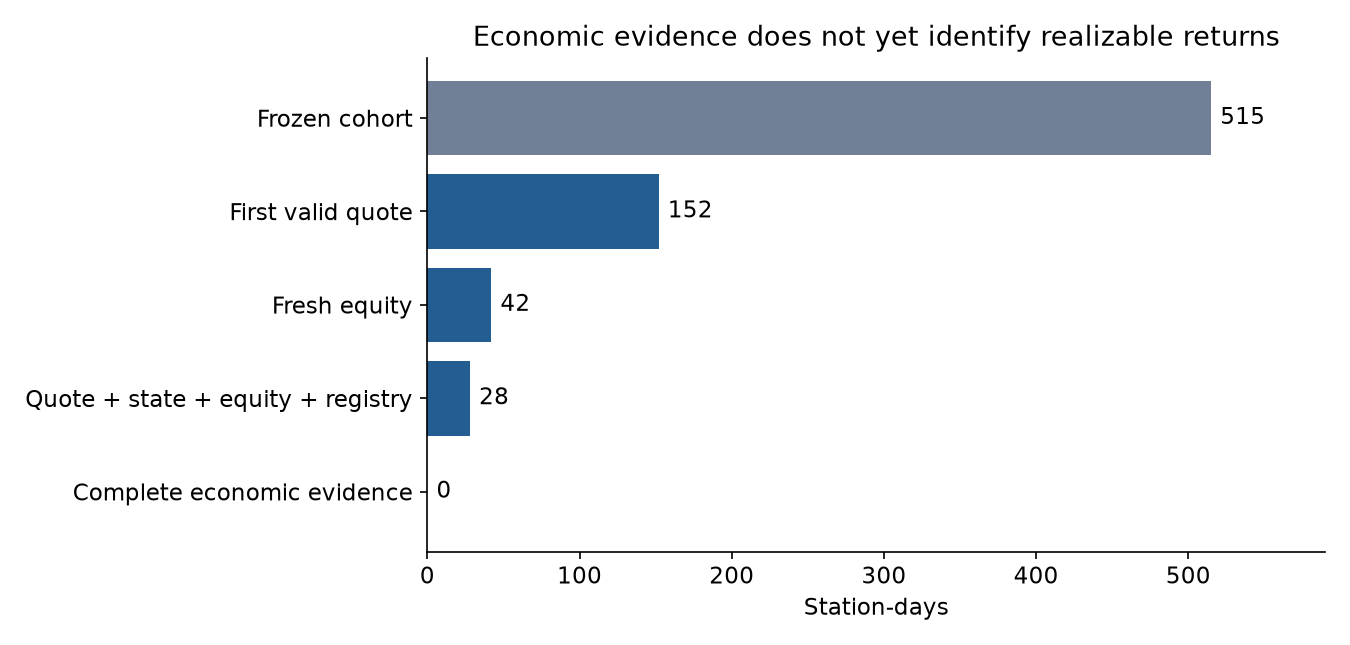

In [5]:
a=json.loads((base/'execution_audit.json').read_text())
fee=json.loads((base/'nested_fee_audit.json').read_text())
assert a['economic_status']=='NOT_IDENTIFIED'
print(a['counts']);print(a['capability_counts']);print('Nested fee fields found on scopes:',fee['scopes_with_any_fee_field'])
fig,ax=plt.subplots(figsize=(9,4.3))
names=['Frozen cohort','First valid quote','Fresh equity','Quote + state + equity + registry','Complete economic evidence']
values=[515,152,42,28,0]
ax.barh(names,values,color=['#718096','#235D91','#235D91','#235D91','#B57935']);ax.invert_yaxis();ax.set_xlim(0,590)
for i,value in enumerate(values):ax.text(value+6,i,str(value),va='center')
ax.set_xlabel('Station-days');ax.set_title('Economic evidence does not yet identify realizable returns')
fig.tight_layout();fig.savefig(base/'economic_coverage.png',dpi=150);plt.close(fig)
display(Image(filename=str(base/'economic_coverage.png')))

## Takeaways
三个候选保持冻结。概率比较完成，实际 EV/Log-growth 无数值可报。下一步先绑定历史费用/执行合同与共同资本路径，复现完整服务链，再在未参与设计的历史外层比较。来源、算法及缺口见 REPORT.md、ECONOMIC_CONTRACT.md 和各审计 JSON。